In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

csv_path = Path("data/raw/student_mental_health.csv")
if not csv_path.exists():
    csv_path = Path("../data/raw/student_mental_health.csv")

df = pd.read_csv(csv_path)
print("Fichier chargé :", csv_path)
df.head()

Fichier chargé : ../data/raw/student_mental_health.csv


,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


In [2]:
print("Dimensions (lignes, colonnes) :", df.shape)
print("Types :")
print(df.dtypes)
print("\nRésumé :")
df.info()

Dimensions (lignes, colonnes) : (2000, 17)
Types :
Student_ID                         object
Age                                 int64
Gender                             object
Year_of_Study                       int64
Sleep_Hours                       float64
Study_Hours_Per_Week              float64
GPA                               float64
Social_Media_Hours                float64
Screen_Time_Hours                 float64
Physical_Activity                  object
Financial_Stress                  float64
Family_Support                    float64
Attendance_Rate                   float64
Part_Time_Job                      object
Diet_Quality                       object
Previous_Mental_Health_History     object
Mental_Health_Risk                 object
dtype: object

Résumé :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          ------

In [3]:
display(df.head())
display(df.tail())
print("Noms des colonnes :")
print(df.columns.tolist())

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
1995,STU1996,23,Male,2,7.5,20.3,1.89,7.3,10.7,High,8.2,6.3,80.9,No,Average,No,Medium
1996,STU1997,21,Male,2,6.4,16.8,2.14,4.6,5.8,Moderate,4.6,3.5,76.9,Yes,Poor,No,High
1997,STU1998,19,Female,1,4.5,13.1,2.54,7.5,10.0,Low,6.7,8.1,87.9,Yes,NaN,No,High
1998,STU1999,21,Male,3,8.1,22.3,2.62,4.5,6.6,Moderate,6.5,8.4,100.0,No,Good,No,Low
1999,STU2000,19,Female,3,5.9,23.3,2.56,7.6,11.2,High,7.7,8.9,87.6,No,Average,No,Medium


Noms des colonnes :
['Student_ID', 'Age', 'Gender', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Physical_Activity', 'Financial_Stress', 'Family_Support', 'Attendance_Rate', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History', 'Mental_Health_Risk']


In [4]:
manquants = df.isna().sum().sort_values(ascending=False)
print("Valeurs manquantes par colonne :")
print(manquants)
print("\nTotal de cellules manquantes :", df.isna().sum().sum())
print("Lignes comportant au moins une valeur manquante :", df.isna().any(axis=1).sum())

Valeurs manquantes par colonne :
Financial_Stress                  91
Diet_Quality                      69
Sleep_Hours                       62
Social_Media_Hours                58
Family_Support                    54
Attendance_Rate                   47
GPA                               38
Student_ID                         0
Age                                0
Screen_Time_Hours                  0
Study_Hours_Per_Week               0
Gender                             0
Year_of_Study                      0
Physical_Activity                  0
Part_Time_Job                      0
Previous_Mental_Health_History     0
Mental_Health_Risk                 0
dtype: int64

Total de cellules manquantes : 419
Lignes comportant au moins une valeur manquante : 394


In [5]:
print("Lignes exactement dupliquées :", df.duplicated().sum())
print("Student_ID dupliqués :", df["Student_ID"].duplicated().sum())
print("Cible manquante :", df["Mental_Health_Risk"].isna().sum())

Lignes exactement dupliquées : 0
Student_ID dupliqués : 0
Cible manquante : 0


In [6]:
print("Âge minimum / maximum :", df["Age"].min(), df["Age"].max())
print("GPA minimum / maximum :", df["GPA"].min(), df["GPA"].max())
print("Présence de taux de présence hors 0–100 :", ((df["Attendance_Rate"] < 0) | (df["Attendance_Rate"] > 100)).sum())
print("Sommeil négatif ou > 24 h :", ((df["Sleep_Hours"] < 0) | (df["Sleep_Hours"] > 24)).sum())
print("GPA hors 0–4 :", ((df["GPA"] < 0) | (df["GPA"] > 4)).sum())
print("\nValeurs possibles pour les catégories :")
for col in ["Gender", "Physical_Activity", "Part_Time_Job", "Diet_Quality", "Previous_Mental_Health_History", "Mental_Health_Risk"]:
    print(col, ":", df[col].dropna().unique())

Âge minimum / maximum : 17 29
GPA minimum / maximum : 1.5 3.66
Présence de taux de présence hors 0–100 : 0
Sommeil négatif ou > 24 h : 0
GPA hors 0–4 : 0

Valeurs possibles pour les catégories :
Gender : ['Male' 'Female' 'Non-binary']
Physical_Activity : ['Moderate' 'Low' 'High']
Part_Time_Job : ['No' 'Yes']
Diet_Quality : ['Poor' 'Average' 'Good']
Previous_Mental_Health_History : ['No' 'Yes']
Mental_Health_Risk : ['High' 'Medium' 'Low']


In [7]:
colonnes_numeriques = df.select_dtypes(include="number").columns

for col in colonnes_numeriques:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    limite_basse = q1 - 1.5 * iqr
    limite_haute = q3 + 1.5 * iqr
    nb_outliers = ((df[col] < limite_basse) | (df[col] > limite_haute)).sum()
    print(col, ":", nb_outliers, "valeur(s) atypique(s) selon IQR")

Age : 4 valeur(s) atypique(s) selon IQR
Year_of_Study : 0 valeur(s) atypique(s) selon IQR
Sleep_Hours : 2 valeur(s) atypique(s) selon IQR
Study_Hours_Per_Week : 7 valeur(s) atypique(s) selon IQR
GPA : 9 valeur(s) atypique(s) selon IQR
Social_Media_Hours : 20 valeur(s) atypique(s) selon IQR
Screen_Time_Hours : 7 valeur(s) atypique(s) selon IQR
Financial_Stress : 0 valeur(s) atypique(s) selon IQR
Family_Support : 0 valeur(s) atypique(s) selon IQR
Attendance_Rate : 12 valeur(s) atypique(s) selon IQR


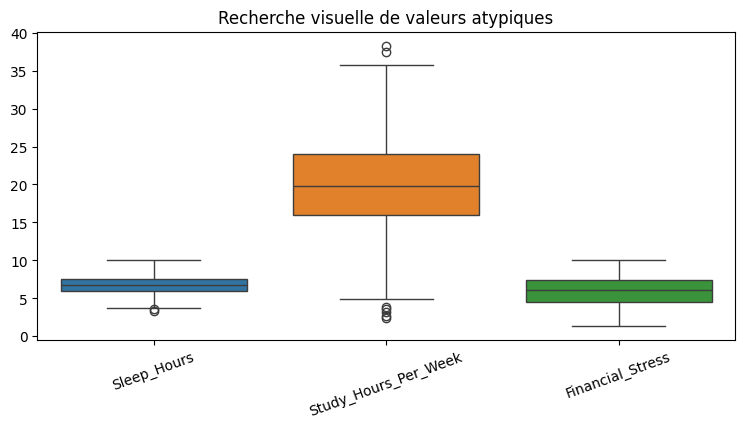

In [8]:
plt.figure(figsize=(9, 4))
sns.boxplot(data=df[["Sleep_Hours", "Study_Hours_Per_Week", "Financial_Stress"]])
plt.title("Recherche visuelle de valeurs atypiques")
plt.xticks(rotation=20)
plt.show()

In [9]:
display(df.describe())
display(df.describe(include="object"))

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
count,2000.000000,2000.000000,1938.000000,2000.000000,1962.000000,1942.000000,2000.000000,1909.000000,1946.000000,1953.000000
mean,21.131500,2.630000,6.758875,19.997900,2.562503,6.013955,8.548500,5.956260,6.518345,85.080236
std,2.139275,1.316802,1.127072,5.719274,0.343993,1.153422,1.657571,1.893941,1.844639,7.224118
min,17.000000,1.000000,3.300000,2.400000,1.500000,2.100000,3.300000,1.400000,1.700000,54.400000
25%,20.000000,1.000000,6.000000,16.000000,2.320000,5.225000,7.400000,4.500000,5.100000,80.300000
50%,21.000000,2.000000,6.700000,19.800000,2.560000,6.000000,8.500000,6.100000,6.700000,85.100000
75%,23.000000,4.000000,7.600000,24.000000,2.790000,6.700000,9.700000,7.400000,8.000000,90.000000
max,29.000000,5.000000,10.000000,38.300000,3.660000,10.000000,14.000000,10.000000,9.900000,100.000000


,Student_ID,Gender,Physical_Activity,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
count,2000,2000,2000,2000,1931,2000,2000
unique,2000,3,3,2,3,2,3
top,STU1984,Female,Moderate,No,Average,No,High
freq,1,971,906,1289,860,1408,680


Effectifs :
Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64

Pourcentages :
Mental_Health_Risk
High      34.0
Medium    33.0
Low       33.0
Name: proportion, dtype: float64


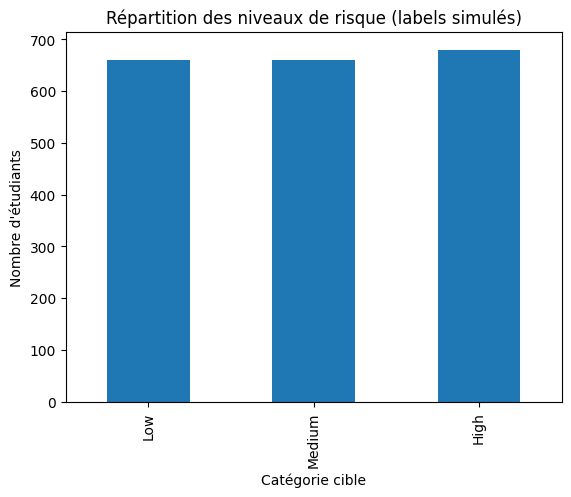

In [10]:
print("Effectifs :")
print(df["Mental_Health_Risk"].value_counts())
print("\nPourcentages :")
print(df["Mental_Health_Risk"].value_counts(normalize=True).mul(100).round(2))

ordre = ["Low", "Medium", "High"]
df["Mental_Health_Risk"].value_counts().reindex(ordre).plot(kind="bar")
plt.title("Répartition des niveaux de risque (labels simulés)")
plt.xlabel("Catégorie cible")
plt.ylabel("Nombre d'étudiants")
plt.show()

In [11]:
variables_a_comparer = ["Sleep_Hours", "Financial_Stress", "Family_Support", "GPA"]
moyennes = df.groupby("Mental_Health_Risk")[variables_a_comparer].mean()
display(moyennes.loc[ordre].round(2))

,Sleep_Hours,Financial_Stress,Family_Support,GPA
Mental_Health_Risk,,,,
Low,7.52,5.24,7.09,2.72
Medium,6.73,5.90,6.53,2.55
High,6.04,6.69,5.96,2.42


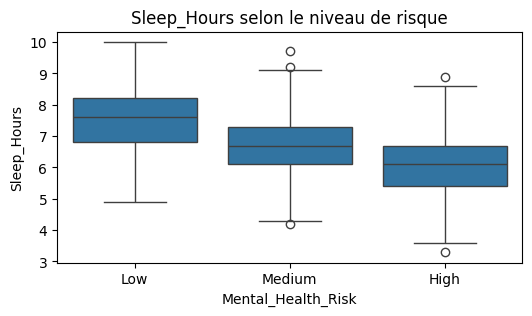

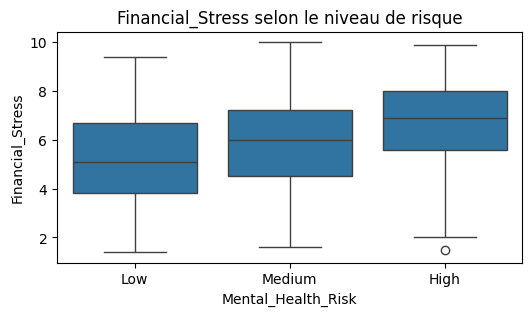

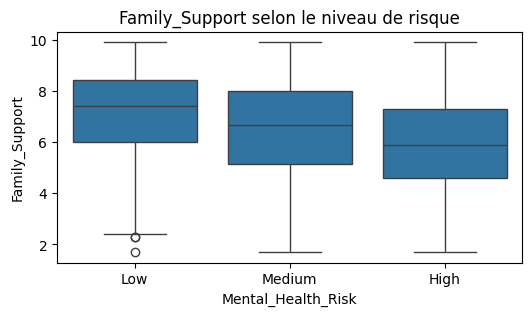

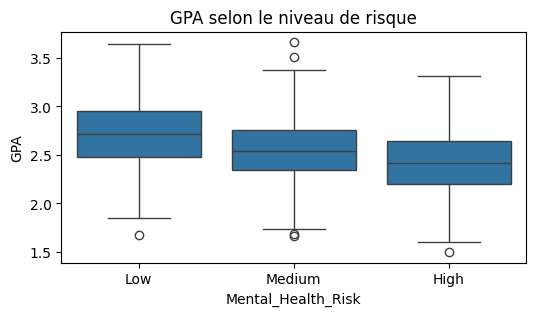

In [12]:
for col in variables_a_comparer:
    plt.figure(figsize=(6, 3))
    sns.boxplot(data=df, x="Mental_Health_Risk", y=col, order=ordre)
    plt.title(f"{col} selon le niveau de risque")
    plt.show()

In [13]:
for col in ["Gender", "Physical_Activity", "Diet_Quality", "Part_Time_Job", "Previous_Mental_Health_History"]:
    print("\n", col)
    tableau = pd.crosstab(df[col], df["Mental_Health_Risk"], normalize="index") * 100
    display(tableau.round(1))


 Gender


Mental_Health_Risk,High,Low,Medium
Gender,,,
Female,34.6,33.5,31.9
Male,33.4,31.8,34.9
Non-binary,34.0,40.2,25.8



 Physical_Activity


Mental_Health_Risk,High,Low,Medium
Physical_Activity,,,
High,20.2,49.4,30.4
Low,45.9,22.8,31.2
Moderate,31.3,33.1,35.5



 Diet_Quality


Mental_Health_Risk,High,Low,Medium
Diet_Quality,,,
Average,32.3,33.5,34.2
Good,27.5,42.8,29.8
Poor,42.2,24.0,33.7



 Part_Time_Job


Mental_Health_Risk,High,Low,Medium
Part_Time_Job,,,
No,30.3,36.2,33.5
Yes,40.8,27.1,32.1



 Previous_Mental_Health_History


Mental_Health_Risk,High,Low,Medium
Previous_Mental_Health_History,,,
No,27.4,39.3,33.3
Yes,49.7,18.1,32.3
